# AI counting (fine-tuned YOLO11n-seg)

Walk-through of the AI solution. The training method is described in `README.md`.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

from count import Counter, overlay

DATA = Path("../../../data")  # unzipped dataset (not stored in git)
counter = Counter()  # model/items_yolo11n_seg.pt, confidence 0.35
plt.rcParams["figure.dpi"] = 60


def show(images, titles, size=6):
    """Show images side by side, downscaled to keep the notebook small."""
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size), squeeze=False)
    for ax, img, title in zip(axes[0], images, titles, strict=True):
        small = cv2.resize(img, None, fx=0.4, fy=0.4, interpolation=cv2.INTER_AREA)
        ax.imshow(cv2.cvtColor(small, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 1. Training data

Automatically labelled 640 px tiles (see `make_dataset.py`).

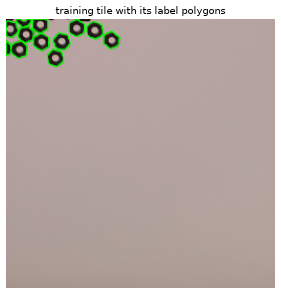

In [2]:
tiles = sorted(Path("datasets/items/train/images").glob("*194541*.jpg"))
if tiles:
    tile = cv2.imread(str(tiles[5]))
    label_file = Path(str(tiles[5]).replace("/images/", "/labels/")).with_suffix(".txt")
    for line in label_file.read_text().splitlines():
        pts = (np.array(line.split()[1:], float).reshape(-1, 2) * tile.shape[1::-1]).astype(np.int32)
        cv2.polylines(tile, [pts], True, (0, 255, 0), 2)
    show([tile], ["training tile with its label polygons"], size=5)
else:
    print("Run `uv run make_dataset.py <data>` to build the training tiles.")

## 2. Training curves

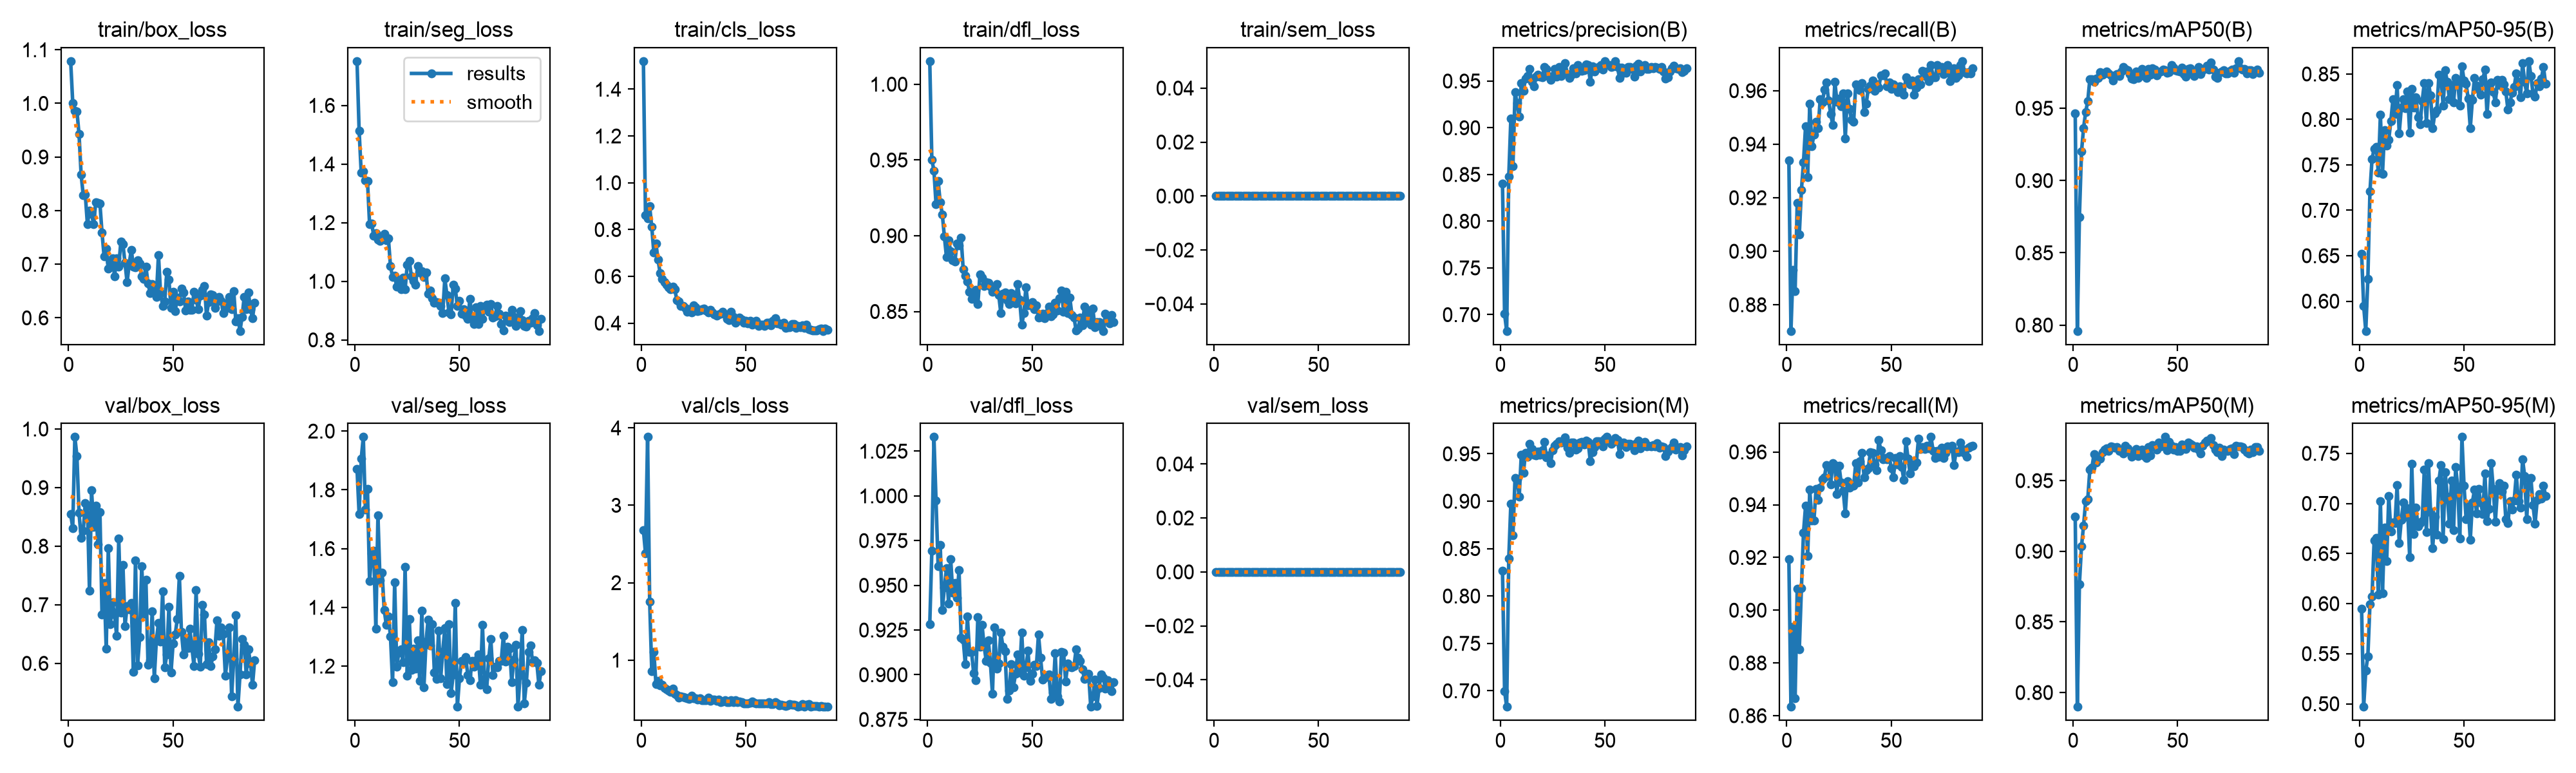

In [3]:
from IPython.display import Image

Image(filename="results/training_curves.png", width=900)

## 3. Held-out test images (never seen in training)

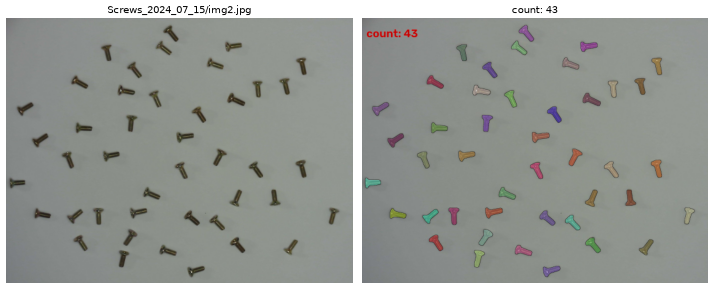

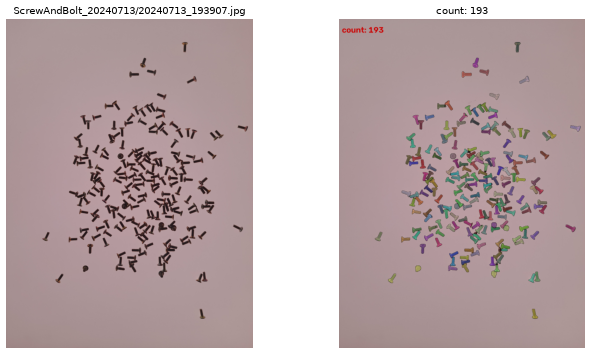

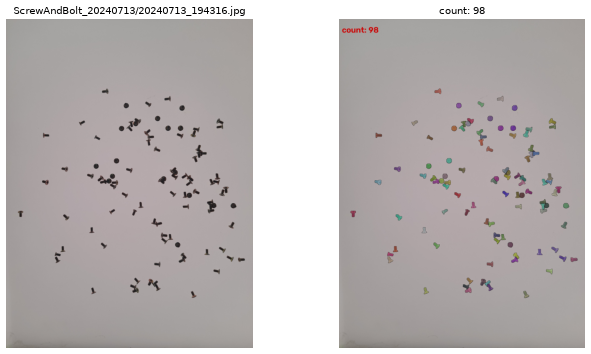

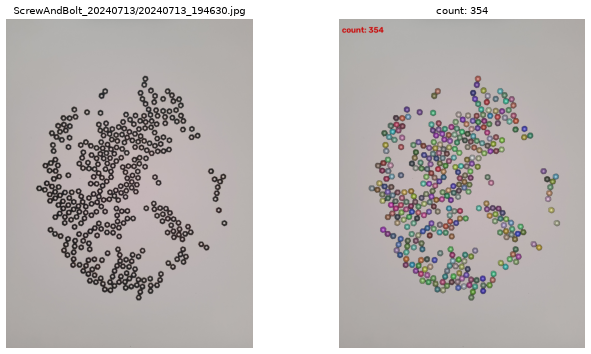

In [4]:
for name in [
    "Screws_2024_07_15/img2.jpg",
    "ScrewAndBolt_20240713/20240713_193907.jpg",
    "ScrewAndBolt_20240713/20240713_194316.jpg",
    "ScrewAndBolt_20240713/20240713_194630.jpg",
]:
    res = counter(DATA / name)
    show([res.image, overlay(res)], [name, f"count: {res.count}"])

## 4. Accuracy against `../ground_truth.json`

In [5]:
!uv run evaluate.py {DATA} -o outputs

image                                      split  true  pred     acc  match  merge  miss   fp


ScrewAndBolt_20240713/20240713_192951.jpg  train    21    21 100.00%     21      0     0    0


ScrewAndBolt_20240713/20240713_193135.jpg  train    21    22  95.24%     21      0     0    1


ScrewAndBolt_20240713/20240713_193650.jpg  val      10    10 100.00%     10      0     0    0


ScrewAndBolt_20240713/20240713_193659.jpg  test     10    10 100.00%      9      1     0    1


ScrewAndBolt_20240713/20240713_193831.jpg  train   193   193 100.00%    183     10     0   10


... (16 outputs left out)

Screws_2024_07_15/img3.jpg                 train    43    43 100.00%     43      0     0    0


Screws_2024_07_15/img4.jpg                 train    43    43 100.00%     43      0     0    0


Screws_2024_07_15/img5.jpg                 val      43    43 100.00%     43      0     0    0


Screws_2024_07_15/img6.jpg                 train    43    43 100.00%     43      0     0    0

TEST (held out): mean per-image accuracy 99.90% (min 99.48%), total true 699 predicted 698 -> 99.86%
VAL: mean per-image accuracy 99.69% (min 98.47%), total true 701 predicted 698 -> 99.57%
TRAIN: mean per-image accuracy 99.35% (min 95.24%), total true 1907 predicted 1903 -> 99.79%
ALL: mean per-image accuracy 99.53% (min 95.24%), total true 3307 predicted 3299 -> 99.76%
